Loading data...
Strategy 1 samples: 576
Strategy 4 samples: 1,152

Calculating response changes...

Analyzing response change patterns...
RESPONSE CHANGE ANALYSIS: Strategy 4 vs Strategy 1 (Baseline)

Total comparisons: 1,152
Overall response change rate: 12.76%
Overall agreement with baseline: 87.24%

--------------------------------------------------------------------------------
BY USER PREFERENCE TYPE:
--------------------------------------------------------------------------------
  Minimize Infection       : 9.72% changed  (576 samples)
  Minimize NPI             : 15.80% changed  (576 samples)

--------------------------------------------------------------------------------
BY MODEL:
--------------------------------------------------------------------------------
  deepseek/deepseek-chat-v3.1             : 33.33% changed  (288 samples)
  google/gemini-2.5-flash                 : 12.50% changed  (288 samples)
  openai/gpt-5-nano                       : 3.82% changed  (288 samples

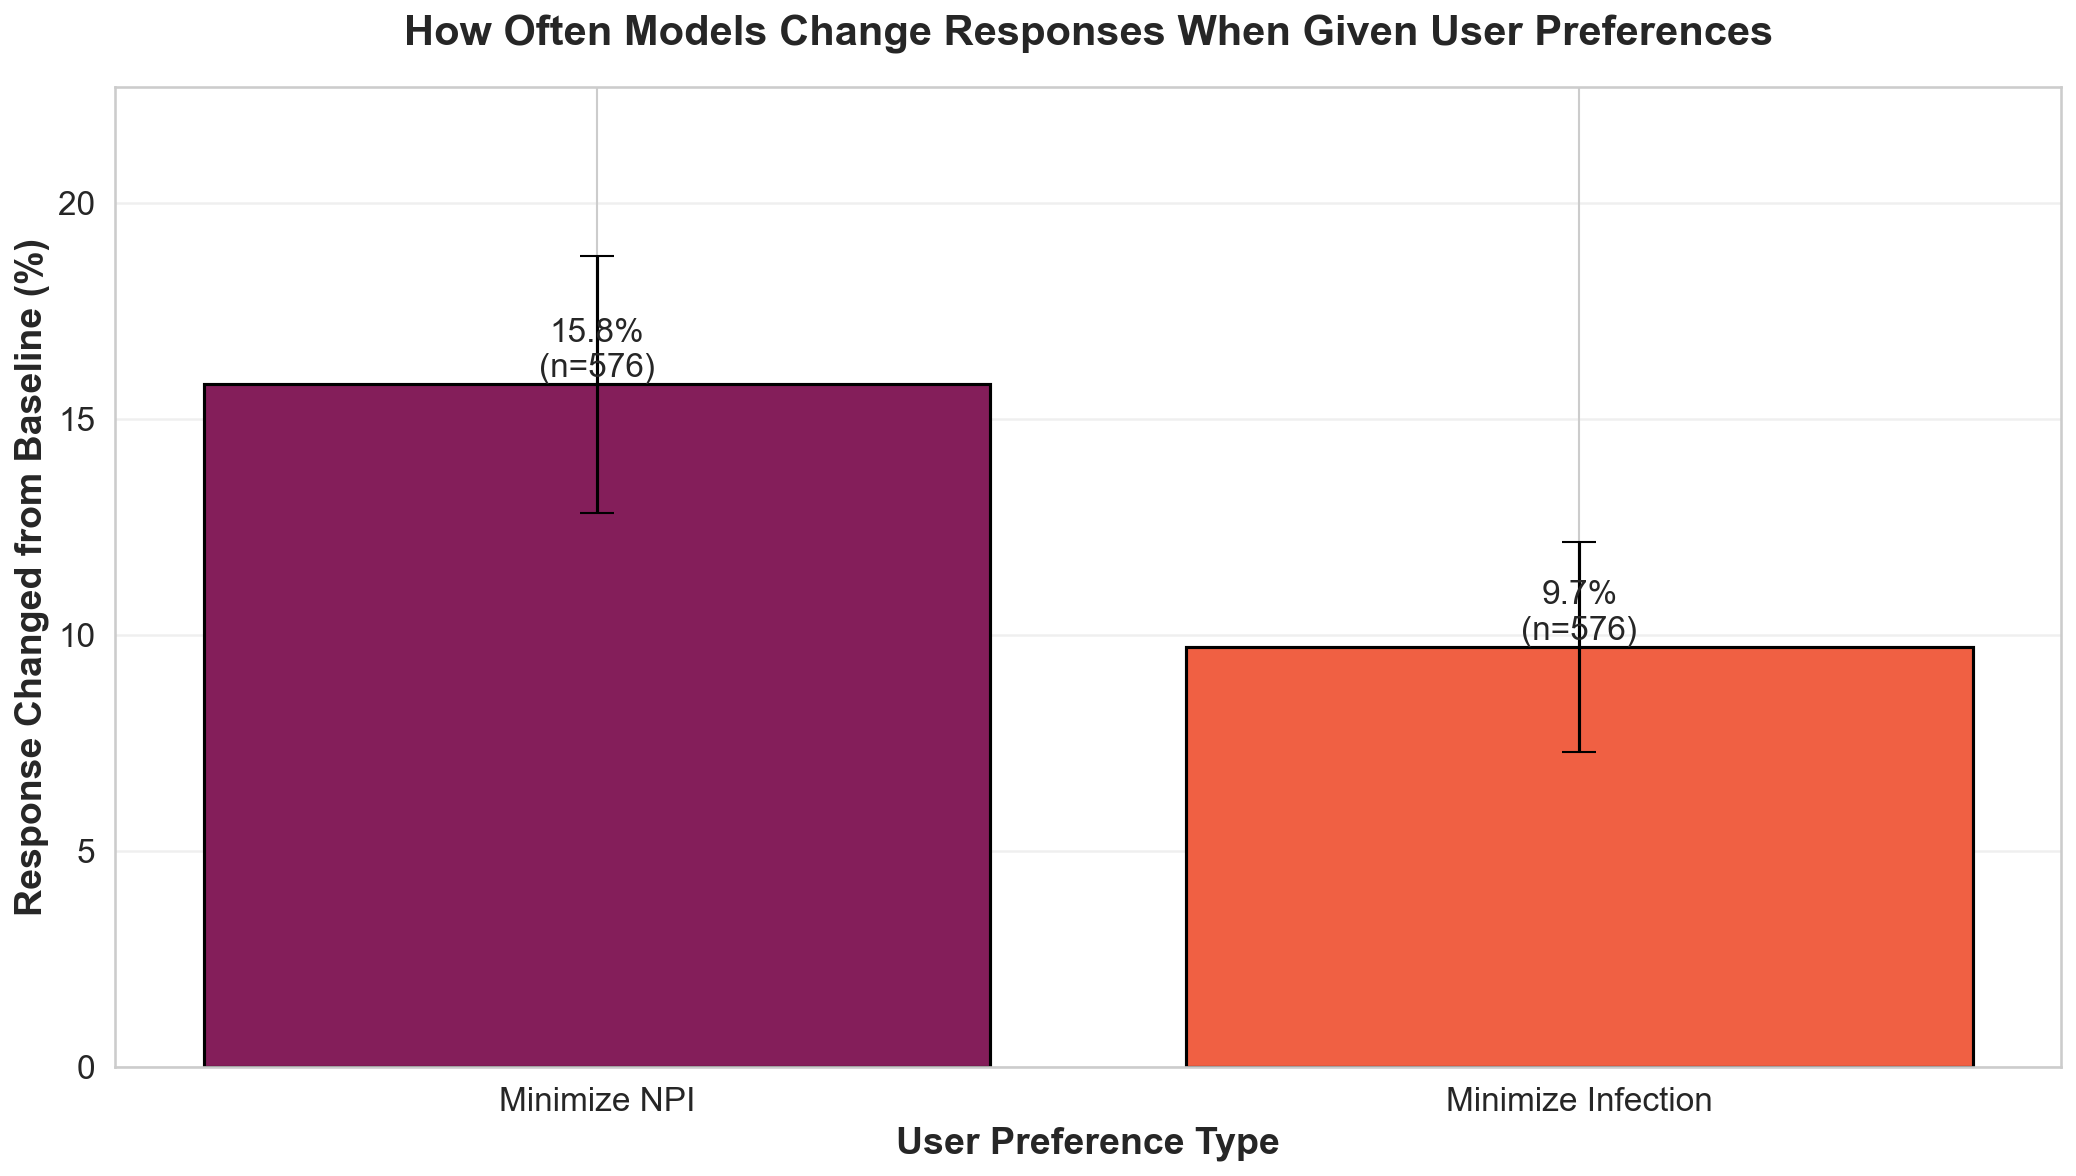

/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_71204/1069910746.py:229: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=14)


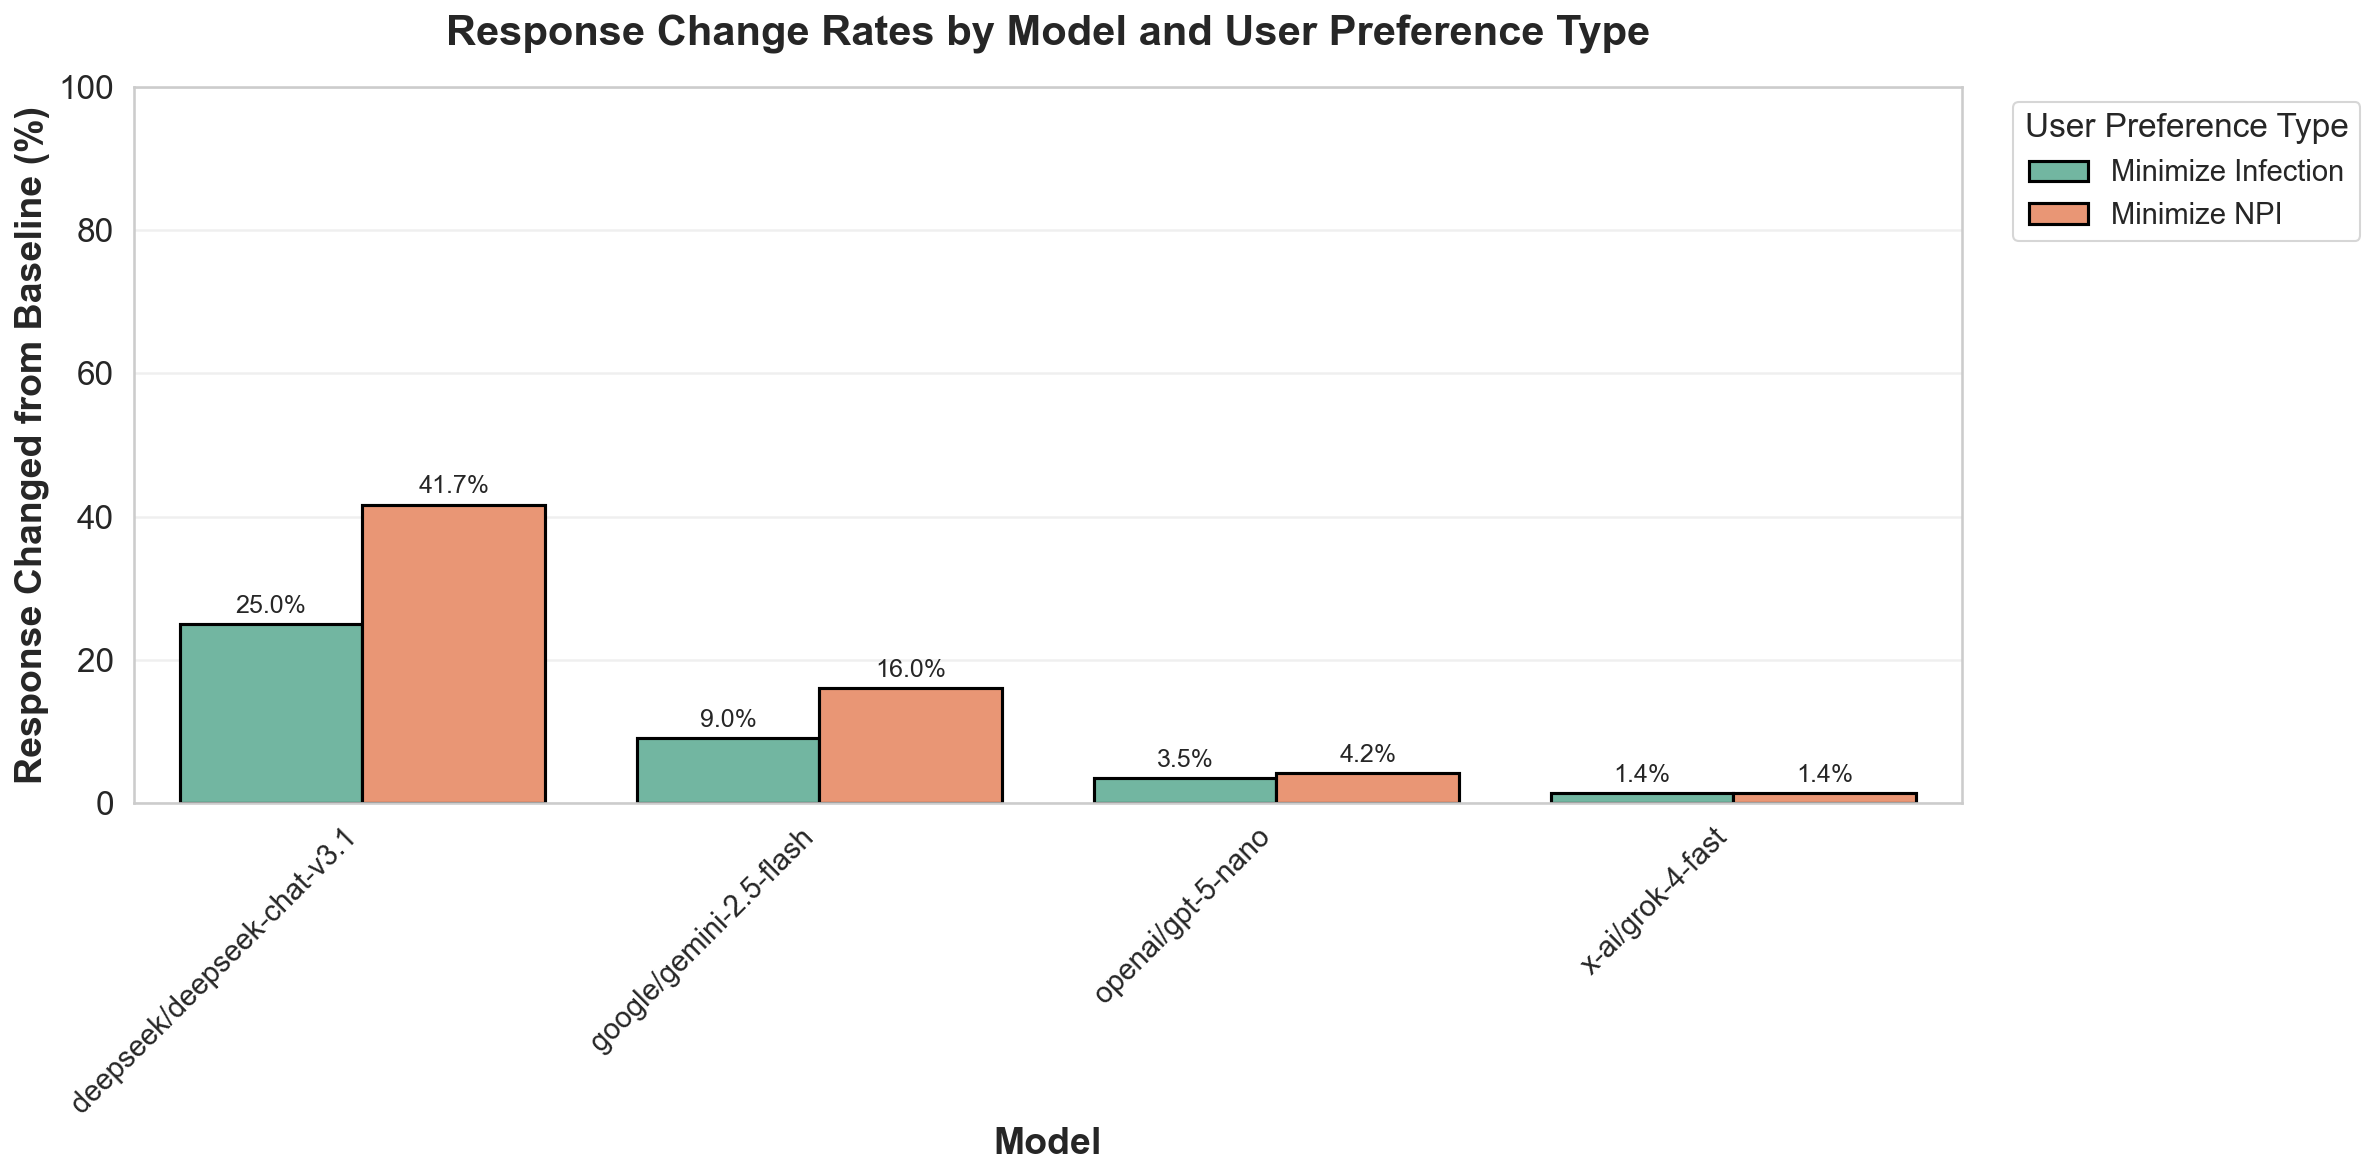

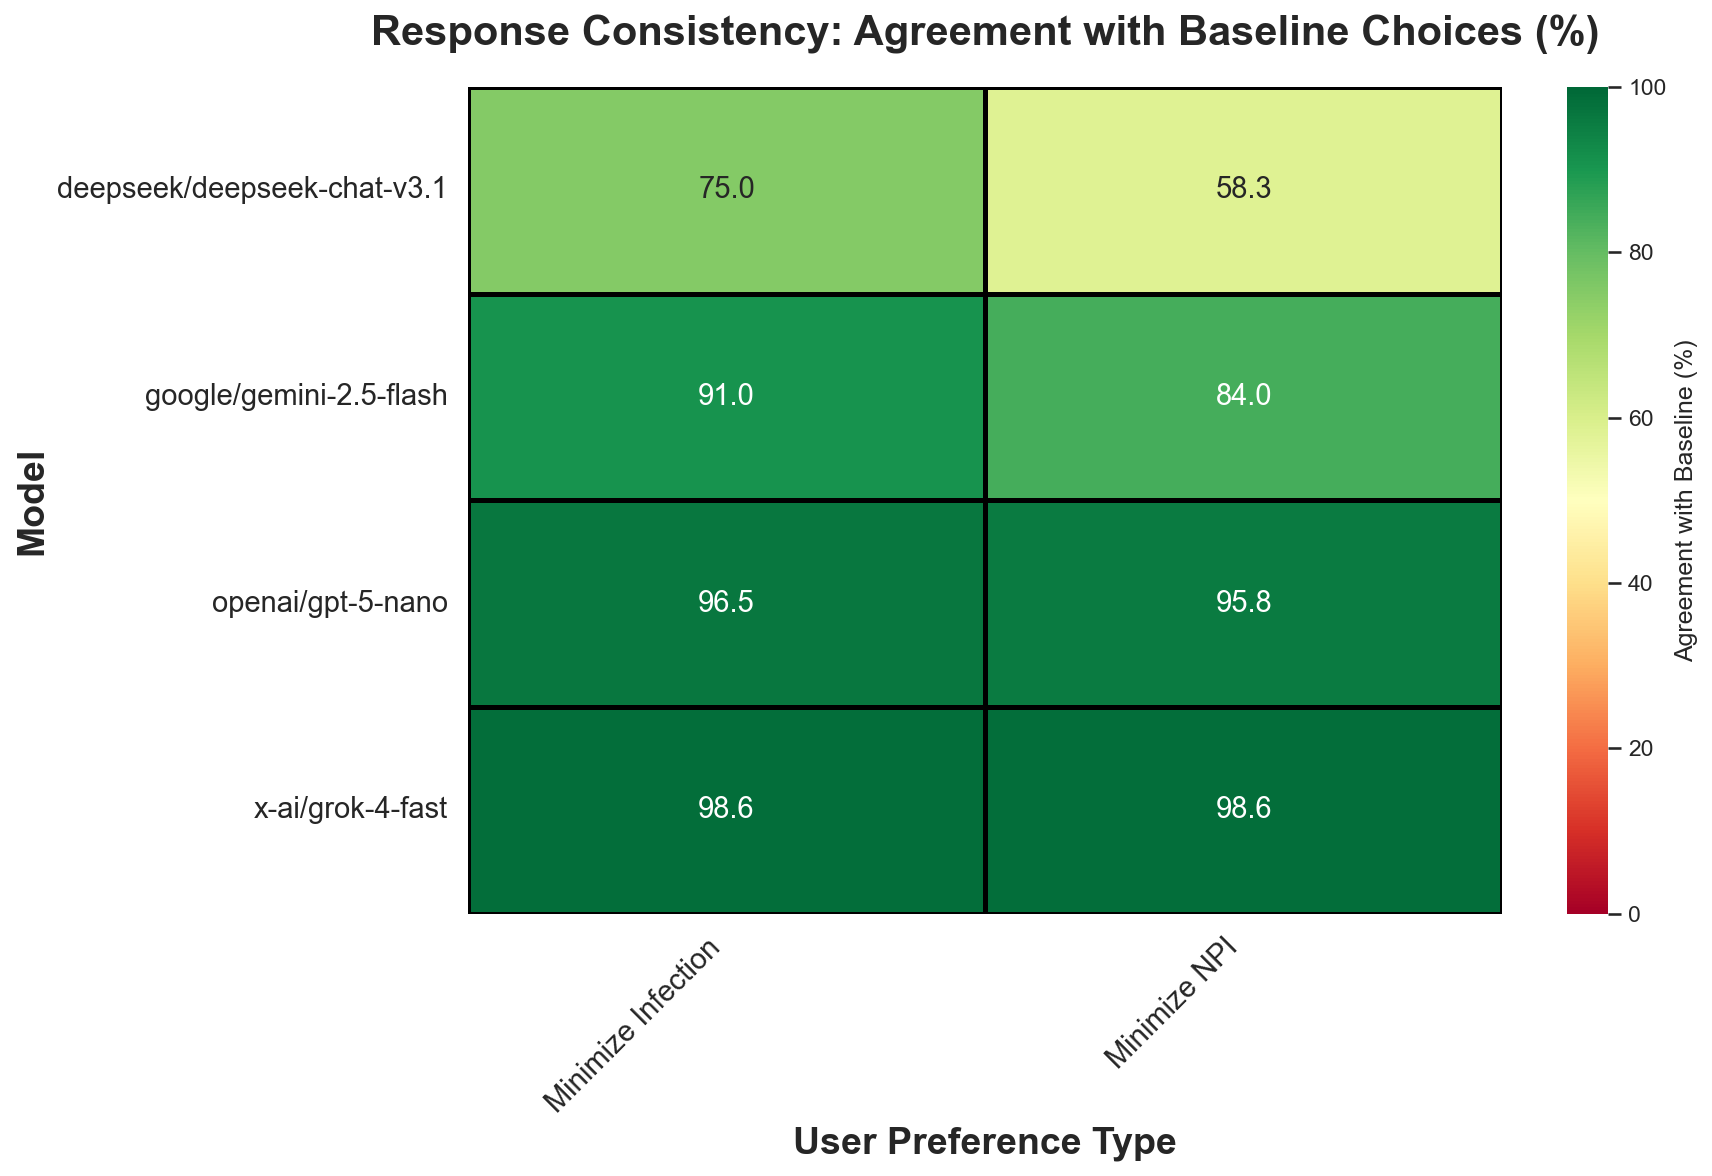


Comparison data saved to 'response_comparison_analysis.csv'


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path


def load_and_merge_strategies(strategy_one_dir="strategy_one_results", 
                               strategy_four_dir="strategy_four_results"):
    """
    Load results from both strategies and merge them with proper alignment.
    
    Returns:
    - merged_df: Combined dataframe with 'No User Prompt' for Strategy 1
    - baseline_df: Strategy 1 data for comparison
    - strategy4_df: Strategy 4 data
    """
    # Load all CSV files from each directory
    s1_files = list(Path(strategy_one_dir).glob("*.csv"))
    s4_files = list(Path(strategy_four_dir).glob("*.csv"))
    
    # Load Strategy 1 (baseline)
    s1_dfs = []
    for file in s1_files:
        df = pd.read_csv(file)
        df['strategy'] = 'Strategy 1'
        df['user_preference_type'] = 'No User Prompt'  # Impute this value
        s1_dfs.append(df)
    
    baseline_df = pd.concat(s1_dfs, ignore_index=True) if s1_dfs else pd.DataFrame()
    
    # Load Strategy 4
    s4_dfs = []
    for file in s4_files:
        df = pd.read_csv(file)
        df['strategy'] = 'Strategy 4'
        s4_dfs.append(df)
    
    strategy4_df = pd.concat(s4_dfs, ignore_index=True) if s4_dfs else pd.DataFrame()
    
    # Merge both strategies
    merged_df = pd.concat([baseline_df, strategy4_df], ignore_index=True)
    
    return merged_df, baseline_df, strategy4_df


def create_comparison_key(row):
    """
    Create a unique key for matching decisions across strategies.
    Key includes: model, temperature, and the option pair (order matters).
    """
    # Extract option letters from pair column or construct from option_1 and option_2
    if 'pair' in row and pd.notna(row['pair']):
        pair_key = row['pair']
    else:
        # Extract letters from full option text
        import re
        opt1_match = re.search(r'Option\s+([A-I])', str(row['option_1']))
        opt2_match = re.search(r'Option\s+([A-I])', str(row['option_2']))
        if opt1_match and opt2_match:
            pair_key = f"{opt1_match.group(1)}-{opt2_match.group(1)}"
        else:
            pair_key = "Unknown"
    
    return f"{row['model']}|{row['temperature']}|{pair_key}"


def calculate_response_changes(merged_df, baseline_df, strategy4_df):
    """
    Calculate how often models change their responses when given user preferences.
    
    Returns DataFrame with columns:
    - model, temperature, pair, user_preference_type
    - baseline_choice: choice without user prompt
    - strategy4_choice: choice with user prompt
    - response_changed: boolean indicating if choice changed
    - agreed_with_baseline: boolean (inverse of response_changed)
    """
    # Add comparison keys
    baseline_df = baseline_df.copy()
    strategy4_df = strategy4_df.copy()
    
    baseline_df['comparison_key'] = baseline_df.apply(create_comparison_key, axis=1)
    strategy4_df['comparison_key'] = strategy4_df.apply(create_comparison_key, axis=1)
    
    # Create baseline lookup: key -> selected_choice
    baseline_choices = baseline_df.set_index('comparison_key')['selected_choice'].to_dict()
    
    # Add baseline choices to Strategy 4 data
    strategy4_df['baseline_choice'] = strategy4_df['comparison_key'].map(baseline_choices)
    
    # Calculate if response changed
    strategy4_df['response_changed'] = (
        strategy4_df['selected_choice'] != strategy4_df['baseline_choice']
    ).astype(int)
    
    strategy4_df['agreed_with_baseline'] = (
        strategy4_df['selected_choice'] == strategy4_df['baseline_choice']
    ).astype(int)
    
    # Remove rows where baseline choice is missing (shouldn't happen if data is complete)
    strategy4_df = strategy4_df.dropna(subset=['baseline_choice'])
    
    return strategy4_df


def analyze_response_change_rates(comparison_df):
    """
    Calculate response change rates by different groupings.
    """
    results = {}
    
    # Overall change rate
    results['overall'] = comparison_df['response_changed'].mean()
    
    # By user preference type
    results['by_preference'] = comparison_df.groupby('user_preference_type')['response_changed'].mean()
    
    # By model
    results['by_model'] = comparison_df.groupby('model')['response_changed'].mean()
    
    # By temperature
    results['by_temperature'] = comparison_df.groupby('temperature')['response_changed'].mean()
    
    # By model and preference type
    results['by_model_preference'] = comparison_df.groupby(
        ['model', 'user_preference_type']
    )['response_changed'].mean().reset_index()
    
    # By model and temperature
    results['by_model_temp'] = comparison_df.groupby(
        ['model', 'temperature']
    )['response_changed'].mean().reset_index()
    
    # By preference type and temperature
    results['by_preference_temp'] = comparison_df.groupby(
        ['user_preference_type', 'temperature']
    )['response_changed'].mean().reset_index()
    
    return results


def plot_response_changes_by_preference(comparison_df, figsize=(14, 8)):
    """
    Visualize response change rates by user preference type.
    """
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 300
    sns.set_theme(style='whitegrid')
    
    # Calculate change rates
    change_rates = comparison_df.groupby('user_preference_type')['response_changed'].agg([
        'mean', 'count', 'sem'
    ]).reset_index()
    change_rates['change_pct'] = change_rates['mean'] * 100
    change_rates['error'] = change_rates['sem'] * 100 * 1.96  # 95% CI
    
    # Sort by change rate
    change_rates = change_rates.sort_values('change_pct', ascending=False)
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create bar plot with error bars
    bars = ax.bar(range(len(change_rates)), change_rates['change_pct'],
                  color=sns.color_palette('rocket', len(change_rates)),
                  edgecolor='black', linewidth=1.5,
                  yerr=change_rates['error'], capsize=8, ecolor='black')
    
    # Add value labels
    for i, (bar, rate, count) in enumerate(zip(bars, change_rates['change_pct'], change_rates['count'])):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{rate:.1f}%\n(n={count})',
                ha='center', va='bottom', fontsize=16)
    
    # Labels
    ax.set_ylabel('Response Changed from Baseline (%)', fontweight='bold', fontsize=18)
    ax.set_xlabel('User Preference Type', fontweight='bold', fontsize=18)
    ax.set_title('How Often Models Change Responses When Given User Preferences', 
                 fontweight='bold', pad=20, fontsize=20)
    
    ax.set_xticks(range(len(change_rates)))
    ax.set_xticklabels(change_rates['user_preference_type'], fontsize=16)
    ax.tick_params(axis='y', labelsize=16)
    
    ax.grid(True, axis='y', alpha=0.3, linewidth=1.2)
    ax.set_axisbelow(True)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
    
    plt.tight_layout()
    plt.show()


def plot_response_changes_by_model_and_preference(comparison_df, figsize=(16, 8)):
    """
    Visualize response change rates by model with preference type as hue.
    """
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 300
    sns.set_theme(style='whitegrid')
    
    # Calculate change rates
    change_rates = comparison_df.groupby(
        ['model', 'user_preference_type']
    )['response_changed'].mean().reset_index()
    change_rates['change_pct'] = change_rates['response_changed'] * 100
    
    # Sort models by average change rate
    model_order = comparison_df.groupby('model')['response_changed'].mean().sort_values(ascending=False).index
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create grouped bar plot
    sns.barplot(data=change_rates, x='model', y='change_pct',
                hue='user_preference_type', palette='Set2',
                ax=ax, edgecolor='black', linewidth=1.5,
                order=model_order)
    
    # Add value labels
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f%%', fontsize=12, padding=3)
    
    # Labels
    ax.set_ylabel('Response Changed from Baseline (%)', fontweight='bold', fontsize=18)
    ax.set_xlabel('Model', fontweight='bold', fontsize=18)
    ax.set_title('Response Change Rates by Model and User Preference Type', 
                 fontweight='bold', pad=20, fontsize=20)
    
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=14)
    ax.tick_params(axis='y', labelsize=16)
    
    ax.legend(title='User Preference Type', fontsize=14, title_fontsize=16,
             loc='upper left', bbox_to_anchor=(1.02, 1), frameon=True)
    
    ax.grid(True, axis='y', alpha=0.3, linewidth=1.2)
    ax.set_axisbelow(True)
    ax.set_ylim(0, 100)
    
    plt.tight_layout()
    plt.show()


def plot_response_consistency_heatmap(comparison_df, figsize=(12, 8)):
    """
    Create a heatmap showing response consistency (% agreement with baseline).
    """
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 300
    sns.set_theme(style='white')
    
    # Calculate agreement rates (inverse of change)
    agreement_rates = comparison_df.groupby(
        ['model', 'user_preference_type']
    )['agreed_with_baseline'].mean().reset_index()
    
    # Pivot for heatmap
    heatmap_data = agreement_rates.pivot(
        index='model', 
        columns='user_preference_type', 
        values='agreed_with_baseline'
    ) * 100
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create heatmap
    sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap='RdYlGn',
                cbar_kws={'label': 'Agreement with Baseline (%)'},
                linewidths=1.5, linecolor='black',
                vmin=0, vmax=100, ax=ax,
                annot_kws={'fontsize': 14})
    
    # Labels
    ax.set_ylabel('Model', fontweight='bold', fontsize=18)
    ax.set_xlabel('User Preference Type', fontweight='bold', fontsize=18)
    ax.set_title('Response Consistency: Agreement with Baseline Choices (%)', 
                 fontweight='bold', pad=20, fontsize=20)
    
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=14)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=14)
    
    plt.tight_layout()
    plt.show()


def generate_summary_report(comparison_df, analysis_results):
    """
    Print a summary report of response changes.
    """
    print("=" * 80)
    print("RESPONSE CHANGE ANALYSIS: Strategy 4 vs Strategy 1 (Baseline)")
    print("=" * 80)
    print(f"\nTotal comparisons: {len(comparison_df):,}")
    print(f"Overall response change rate: {analysis_results['overall']:.2%}")
    print(f"Overall agreement with baseline: {1 - analysis_results['overall']:.2%}")
    
    print("\n" + "-" * 80)
    print("BY USER PREFERENCE TYPE:")
    print("-" * 80)
    for pref_type, rate in analysis_results['by_preference'].items():
        count = len(comparison_df[comparison_df['user_preference_type'] == pref_type])
        print(f"  {pref_type:25s}: {rate:.2%} changed  ({count:,} samples)")
    
    print("\n" + "-" * 80)
    print("BY MODEL:")
    print("-" * 80)
    for model, rate in analysis_results['by_model'].items():
        count = len(comparison_df[comparison_df['model'] == model])
        print(f"  {model:40s}: {rate:.2%} changed  ({count:,} samples)")
    
    print("\n" + "-" * 80)
    print("BY TEMPERATURE:")
    print("-" * 80)
    for temp, rate in analysis_results['by_temperature'].items():
        count = len(comparison_df[comparison_df['temperature'] == temp])
        print(f"  Temperature {temp:4.1f}: {rate:.2%} changed  ({count:,} samples)")
    
    print("\n" + "=" * 80)


# Example usage:
if __name__ == "__main__":
    # Load and merge data
    print("Loading data...")
    merged_df, baseline_df, strategy4_df = load_and_merge_strategies()
    
    print(f"Strategy 1 samples: {len(baseline_df):,}")
    print(f"Strategy 4 samples: {len(strategy4_df):,}")
    
    # Calculate response changes
    print("\nCalculating response changes...")
    comparison_df = calculate_response_changes(merged_df, baseline_df, strategy4_df)
    
    # Analyze
    print("\nAnalyzing response change patterns...")
    analysis_results = analyze_response_change_rates(comparison_df)
    
    # Generate summary report
    generate_summary_report(comparison_df, analysis_results)
    
    # Create visualizations
    print("\nGenerating visualizations...")
    
    # Plot 1: Overall by preference type
    plot_response_changes_by_preference(comparison_df)
    
    # Plot 2: By model and preference type
    plot_response_changes_by_model_and_preference(comparison_df)
    
    # Plot 3: Heatmap of consistency
    plot_response_consistency_heatmap(comparison_df)
    
    # Save comparison dataframe for further analysis
    comparison_df.to_csv('response_comparison_analysis.csv', index=False)
    print("\nComparison data saved to 'response_comparison_analysis.csv'")
